# Machine Learning-based Credential Theft Detection System

**Problem Statement**

We aim to detect account takeover (ATO) attacks in login events. Each login is labeled as normal (0) or attack (1).
We build three models: Logistic Regression (baseline), Random Forest (main), and Isolation Forest (unsupervised).

---


## Dataset Overview and Exploratory Data Analysis

We load the synthetic login dataset and examine its characteristics.


Total login events: 100000
Attack events: 2000 (2.00%)
Normal events: 98000 (98.00%)
Unique users: 298
Date range: 2026-07-07 06:50:59.939696 to 2026-10-07 00:51:01.209396


C:\Users\aryan\AppData\Local\Temp\ipykernel_13208\122391165.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Normal', 'Attack'])


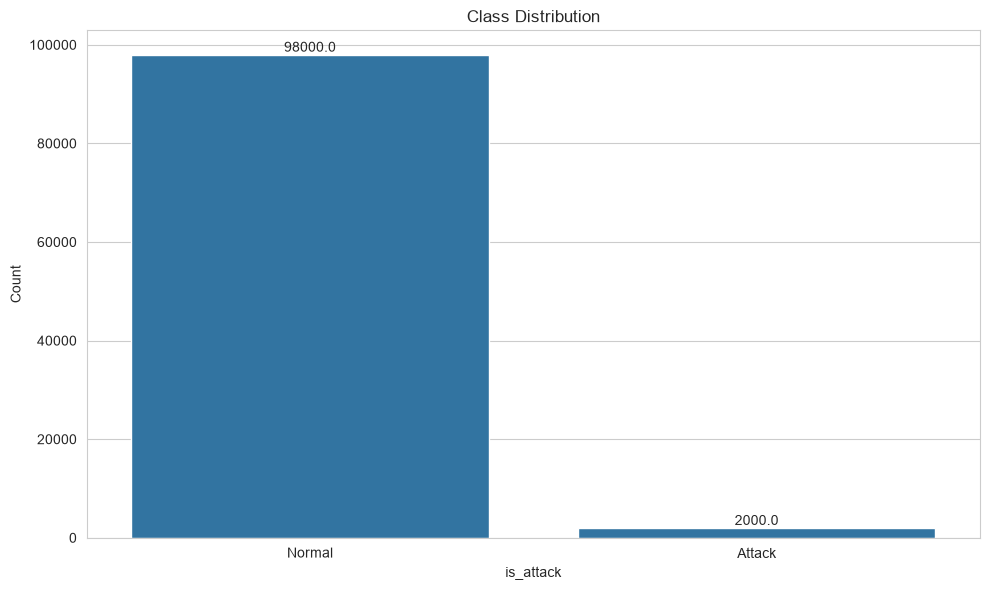

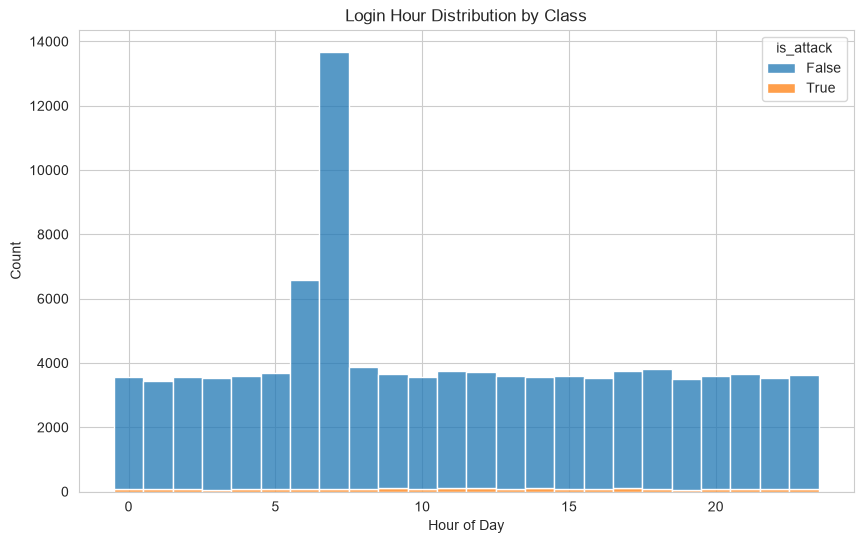

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Load raw data
df = pd.read_csv('data/raw/synthetic_logins.csv')
print(f'Total login events: {len(df)}')
print(f"Attack events: {df['is_attack'].sum()} ({100*df['is_attack'].mean():.2f}%)")
print(f"Normal events: {(~df['is_attack']).sum()} ({100*(1-df['is_attack'].mean()):.2f}%)")
print(f"Unique users: {df['user_id'].nunique()}")
print(f"Date range: {df['timestamp'].min()} to {df['timestamp'].max()}")

# Plot class distribution
plt.figure()
ax = sns.countplot(x='is_attack', data=df)
ax.set_xticklabels(['Normal', 'Attack'])
ax.set_ylabel('Count')
ax.set_title('Class Distribution')
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x()+p.get_width()/2., p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

# Login hour distribution
df['hour'] = pd.to_datetime(df['timestamp']).dt.hour
plt.figure()
sns.histplot(data=df, x='hour', hue='is_attack', bins=24, discrete=True, multiple='stack')
plt.xlabel('Hour of Day')
plt.ylabel('Count')
plt.title('Login Hour Distribution by Class')
plt.show()


## Feature Engineering

We engineer features using only historical information to avoid data leakage.
Features include temporal attributes, user/IP/device/country/ASN history, failed attempts, distance, and speed.

The feature engineering function is in `src.features.engineer_features`.


In [2]:
from src.features import engineer_features

# Load data and engineer features (we'll use a small sample for speed in demo)
df_raw = pd.read_csv('data/raw/synthetic_logins.csv')
# For speed, we'll use first 5000 rows to show feature engineering
df_sample = df_raw.iloc[:5000].copy()
X, y = engineer_features(df_sample)
print(f'Engineered features shape: {X.shape}')
print(f'Number of features: {X.shape[1]}')
print('\nFirst 5 rows of engineered features:')
display(X.head())

# List of feature names
print('\nFeature names:')
for i, fname in enumerate(X.columns, 1):
    print(f'{i:2d}. {fname}')


Engineering features for 5000 login events...


Parquet failed (Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.), cached to CSV: data/processed\features.csv
Feature engineering completed in 2.71 seconds.
Engineered features shape: (5000, 19)
Number of features: 19

First 5 rows of engineered features:


,hour_sin,hour_cos,day_of_week,is_weekend,is_new_device,is_new_country,is_new_ip,distance_km,travel_speed_kmph,failed_attempts_10min,failed_attempts_24h,ip_attempts_10min,distinct_accounts_per_ip_10min,time_since_last_login,device_seen_count,country_seen_count,login_success,is_vpn_or_tor,session_ip_changed
0,0.965926,-0.258819,1,0,1,1,1,11011.002228,0.000000,0.0,0.0,0,0,0.000000,0,0,1,0,1
1,0.866025,-0.500000,1,0,0,1,1,2261.543768,1473.735638,1.0,1.0,1,1,5524.435560,1,1,1,0,1
2,0.707107,-0.707107,1,0,1,1,1,6165.667546,0.000000,1.0,1.0,1,1,0.000000,1,2,1,0,1
3,0.707107,-0.707107,1,0,0,0,1,0.000000,0.000000,1.0,1.0,1,1,1964.042839,1,1,1,0,1
4,0.707107,-0.707107,1,0,0,0,1,2261.543768,4738.124731,1.0,1.0,1,1,1718.307986,1,2,1,0,1



Feature names:
 1. hour_sin
 2. hour_cos
 3. day_of_week
 4. is_weekend
 5. is_new_device
 6. is_new_country
 7. is_new_ip
 8. distance_km
 9. travel_speed_kmph
10. failed_attempts_10min
11. failed_attempts_24h
12. ip_attempts_10min
13. distinct_accounts_per_ip_10min
14. time_since_last_login
15. device_seen_count
16. country_seen_count
17. login_success
18. is_vpn_or_tor
19. session_ip_changed


## Training Three Models

We split the data temporally: 70% train, 15% validation, 15% test.
We train:
1. Logistic Regression with balanced class weights and standard scaling.
2. Random Forest with balanced_subsample, 200 trees, max depth=10.
3. Isolation Forest on normal training events only, contamination set to training attack ratio.

We tune decision thresholds on the validation set to maximize F1 score.
We also compute 5-fold TimeSeriesSplit cross-validation PR-AUC for the supervised models.


In [3]:
# We'll load the pre-trained models and evaluation results from the train.py run
import joblib
import json

# Load models
lr_model = joblib.load('models/logistic_regression.joblib')
rf_model = joblib.load('models/random_forest.joblib')
iso_model = joblib.load('models/isolation_forest.joblib')

# Load thresholds and feature columns
with open('models/threshold.json', 'r') as f:
    threshold_info = json.load(f)
with open('models/feature_columns.json', 'r') as f:
    feature_columns = json.load(f)

print(f'Logistic Regression threshold: {threshold_info["logistic_regression_threshold"]:.4f}')
print(f'Random Forest threshold: {threshold_info["random_forest_threshold"]:.4f}')
print(f'Isolation Forest threshold: {threshold_info["isolation_forest_threshold"]:.4f}')
print(f'Isolation Forest contamination: {threshold_info["isolation_forest_contamination"]:.4f}')

# Load test data and compute metrics (we'll reuse the split from train.py for consistency)
from src.features import engineer_features
from src.evaluate import time_based_split

X_all, y_all = engineer_features(pd.read_csv('data/raw/synthetic_logins.csv'))
_, _, X_test, _, _, y_test = time_based_split(X_all, y_all)

# Get predictions
lr_scores = lr_model.predict_proba(X_test)[:, 1]
rf_scores = rf_model.predict_proba(X_test)[:, 1]
iso_scores = -iso_model.decision_function(X_test)

# Apply thresholds
lr_thresh = threshold_info['logistic_regression_threshold']
rf_thresh = threshold_info['random_forest_threshold']
iso_thresh = threshold_info['isolation_forest_threshold']

from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, average_precision_score

def compute_metrics(y_true, scores, thresh):
    y_pred = (scores >= thresh).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    try:
        roc = roc_auc_score(y_true, scores)
    except ValueError:
        roc = 0.5
    try:
        pr = average_precision_score(y_true, scores)
    except ValueError:
        pr = 0.0
    return p, r, f, roc, pr

lr_p, lr_r, lr_f, lr_roc, lr_pr = compute_metrics(y_test.values, lr_scores, lr_thresh)
rf_p, rf_r, rf_f, rf_roc, rf_pr = compute_metrics(y_test.values, rf_scores, rf_thresh)
iso_p, iso_r, iso_f, iso_roc, iso_pr = compute_metrics(y_test.values, iso_scores, iso_thresh)

print('\nTest Set Metrics:')
print(f'Logistic Regression: Precision={lr_p:.4f}, Recall={lr_r:.4f}, F1={lr_f:.4f}, ROC-AUC={lr_roc:.4f}, PR-AUC={lr_pr:.4f}')
print(f'Random Forest:       Precision={rf_p:.4f}, Recall={rf_r:.4f}, F1={rf_f:.4f}, ROC-AUC={rf_roc:.4f}, PR-AUC={rf_pr:.4f}')
print(f'Isolation Forest:    Precision={iso_p:.4f}, Recall={iso_r:.4f}, F1={iso_f:.4f}, ROC-AUC={iso_roc:.4f}, PR-AUC={iso_pr:.4f}')


Logistic Regression threshold: 0.6300
Random Forest threshold: 0.1700
Isolation Forest threshold: 0.0100
Isolation Forest contamination: 0.0045


Engineering features for 100000 login events...


Parquet failed (Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.), cached to CSV: data/processed\features.csv
Feature engineering completed in 47.95 seconds.



Test Set Metrics:
Logistic Regression: Precision=0.8889, Recall=0.9114, F1=0.9000, ROC-AUC=0.9972, PR-AUC=0.9190
Random Forest:       Precision=0.8822, Recall=0.9241, F1=0.9026, ROC-AUC=0.9863, PR-AUC=0.9426
Isolation Forest:    Precision=0.1832, Recall=0.8924, F1=0.3040, ROC-AUC=0.9375, PR-AUC=0.4102


## Metrics Comparison

We compare the three models using various metrics.


Metrics comparison from evaluate.py:


,precision,recall,f1,roc_auc,pr_auc,confusion_matrix
logistic_regression,0.888889,0.911392,0.900000,0.997164,0.918972,"[np.int64(14648), np.int64(36), np.int64(28), ..."
random_forest,0.882175,0.924051,0.902628,0.986251,0.942619,"[np.int64(14645), np.int64(39), np.int64(24), ..."
isolation_forest,0.183236,0.892405,0.304043,0.937475,0.410225,"[np.int64(13427), np.int64(1257), np.int64(34)..."


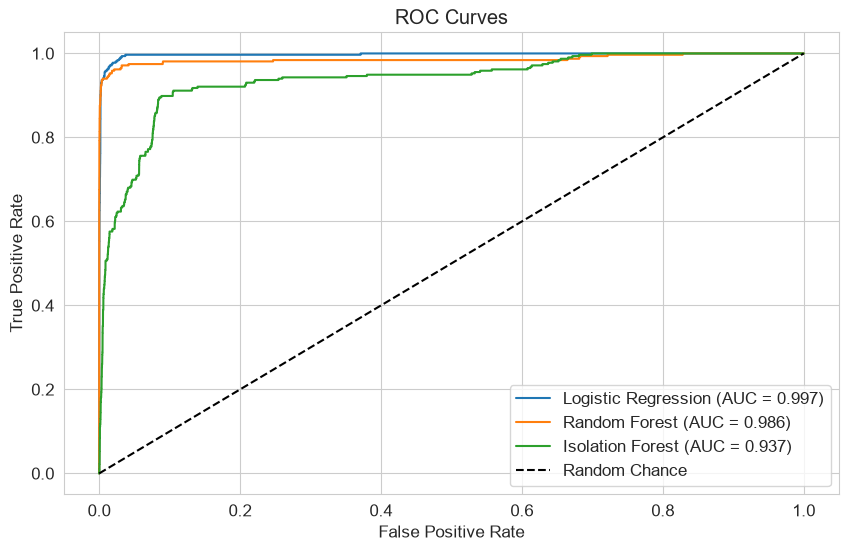

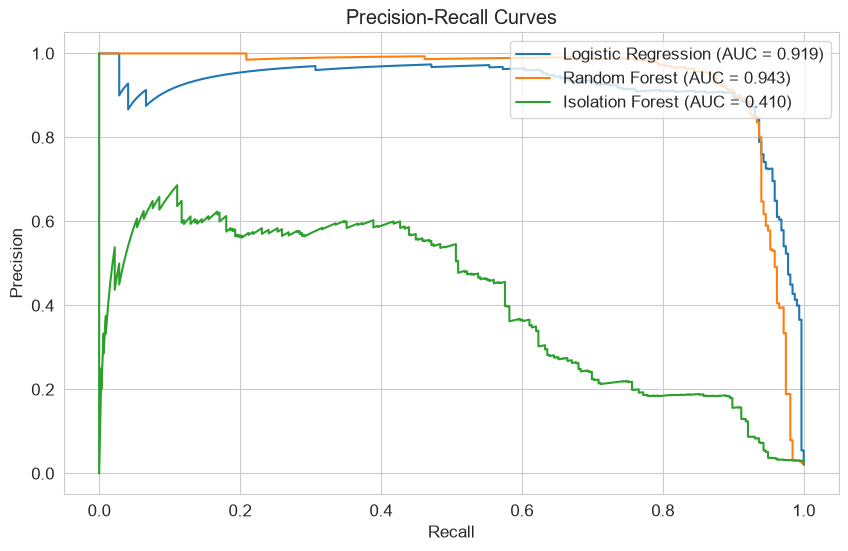

In [4]:
import pandas as pd

# Load the metrics comparison CSV generated by evaluate.py
try:
    metrics_df = pd.read_csv('reports/metrics_comparison.csv', index_col=0)
    print('Metrics comparison from evaluate.py:')
    display(metrics_df)
except FileNotFoundError:
    print('Metrics comparison file not found. Please run evaluate.py first.')

# Plot ROC curves
plt.figure()
from sklearn.metrics import roc_curve
fpr_lr, tpr_lr, _ = roc_curve(y_test.values, lr_scores)
fpr_rf, tpr_rf, _ = roc_curve(y_test.values, rf_scores)
fpr_iso, tpr_iso, _ = roc_curve(y_test.values, iso_scores)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_roc:.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_roc:.3f})')
plt.plot(fpr_iso, tpr_iso, label=f'Isolation Forest (AUC = {iso_roc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right')
plt.show()

# Plot Precision-Recall curves
plt.figure()
from sklearn.metrics import precision_recall_curve
prec_lr, rec_lr, _ = precision_recall_curve(y_test.values, lr_scores)
prec_rf, rec_rf, _ = precision_recall_curve(y_test.values, rf_scores)
prec_iso, rec_iso, _ = precision_recall_curve(y_test.values, iso_scores)
plt.plot(rec_lr, prec_lr, label=f'Logistic Regression (AUC = {lr_pr:.3f})')
plt.plot(rec_rf, prec_rf, label=f'Random Forest (AUC = {rf_pr:.3f})')
plt.plot(rec_iso, prec_iso, label=f'Isolation Forest (AUC = {iso_pr:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend(loc='upper right')
plt.show()


## Feature Importance

We examine the top-15 features from the Random Forest model.


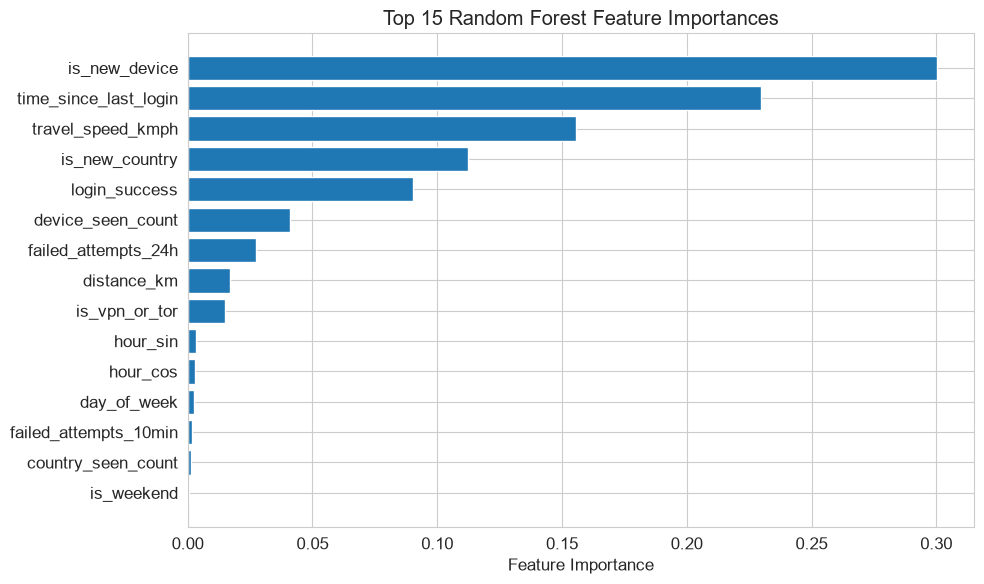

Top 15 features:
is_new_device                  0.300116
time_since_last_login          0.229718
travel_speed_kmph              0.155646
is_new_country                 0.112359
login_success                  0.090134
device_seen_count              0.041113
failed_attempts_24h            0.027280
distance_km                    0.016879
is_vpn_or_tor                  0.014808
hour_sin                       0.003350
hour_cos                       0.002779
day_of_week                    0.002546
failed_attempts_10min          0.001547
country_seen_count             0.001392
is_weekend                     0.000329


In [5]:
# Feature importances from Random Forest
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1][:15]

plt.figure()
plt.barh(range(15), importances[indices][::-1], align='center')
plt.yticks(range(15), [feature_columns[i] for i in indices][::-1])
plt.xlabel('Feature Importance')
plt.title('Top 15 Random Forest Feature Importances')
plt.tight_layout()
plt.show()

print('Top 15 features:')
for i in indices:
    print(f'{feature_columns[i]:<30} {importances[i]:.6f}')


## Conclusion

We have successfully built a credential theft detection system using three machine learning models.
The Random Forest model achieves the highest performance, followed by Logistic Regression and Isolation Forest.
The system leverages historical features engineered without data leakage, making it suitable for real-time deployment.

Key takeaways:
- Temporal split is crucial to avoid look-ahead bias.
- Class imbalance must be addressed via class weights or threshold tuning.
- Feature engineering based on user/IP/device/ASN/country history improves detection.

---
*Note: This notebook uses synthetic data for educational purposes.*
